# Introductie

Tumorgroei is een biologisch proces waarbij cellen zich ongecontroleerd delen, waardoor een tumor in omvang kan toenemen. Het verloop van deze groei kan worden onderzocht met behulp van wiskundige (groei)modellen en Ordinary Differential Equations (ODE's).

In deze user-case onderzoeken we hoe de grootte van een tumor verandert over een periode van 120 dagen. Hiervoor gebruiken we een dataset met meetgegevens van het tumorvolume op verschillende tijdstippen.

Het doel van dit project is om verschillende wiskundige groeimodellen te ontwikkelen en te vergelijken. We onderzoeken drie modellen: het exponentiële, logistische en Gompertz-groeimodel. Met behulp van differentiaalvergelijkingen en ODE-solvers berekenen we de verwachte tumorgroei. Vervolgens gebruiken we een Monte Carlo-simulatie om geschikte parameters te vinden voor elk model.

Tot slot vergelijken we de modellen aan de hand van statistische criteria en visualisaties. Hiermee onderzoeken we welk model de gemeten tumorgroei het beste beschrijft.

**Onderzoeksvraag:**

Welk wiskundig groeimodel beschrijft de gemeten tumorgroei het beste, op basis van de beschikbare meetgegevens en de vergelijking van modelresultaten?

# Dataset

Voor dit project gebruiken wij een dataset uit het volgende artikel: Treatment Optimization for Tumor Growth by Ordinary Differential Equations geschreven door Kenneth Chan, Chiu-Yen Kao, Jennifer Gordinier en Katherine Ganden.

Aangezien de data in het artikel niet in een bijgevoegd bestand te vinden was, hebben wij deze handmatig omgezet naar een csv-bestand. Dit maakt het eenvoudiger om de dataset in te laten lezen in Python.

De dataset bestaat uit een kolom 'Tijd_dagen' en een kolom 'Tumorvolume_mm3', waarbij beide kolommen bestaan uit 16 meetpunten. De beginwaarde van de tijd is 0 en de beginwaarde van tumorvolume is 250 mm^3.

Eerst installeren we alle benodigde libraries om de codeblokken uit te kunnen voeren.

In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import random
import math

Vervolgens lezen we de dataset in met behulp van onderstaande code.

In [15]:
def read_data(filename):
    file_path = Path("..") / "tumor_model" / "data" / filename
    data = pd.read_csv(file_path)

    ts_input = data["Tijd_dagen"].tolist()
    ys_input = data["Tumorvolume_mm3"].tolist()

    print("Tijd:")
    print(ts_input[:3])

    print("\nTumorvolume:")
    print(ys_input[:3])

    print("\nInformatie over de dataset:")
    data.info()

    return ts_input, ys_input

Door de code aan te roepen, wordt de output weergegeven. 
Hiermee kunnen we nagaan of de dataset goed is ingelezen.

In [16]:
ts_input, ys_input = read_data("Hassan_2024.csv")

Tijd:
[0, 13, 20]

Tumorvolume:
[250, 255, 550]

Informatie over de dataset:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Tijd_dagen       15 non-null     int64
 1   Tumorvolume_mm3  15 non-null     int64
dtypes: int64(2)
memory usage: 372.0 bytes


Door de meetpunten mee te geven aan matplotlib, kunnen we een visualisatie genereren.
Op deze manier krijgen we een beter beeld van hoe de data er op dit moment uit ziet.

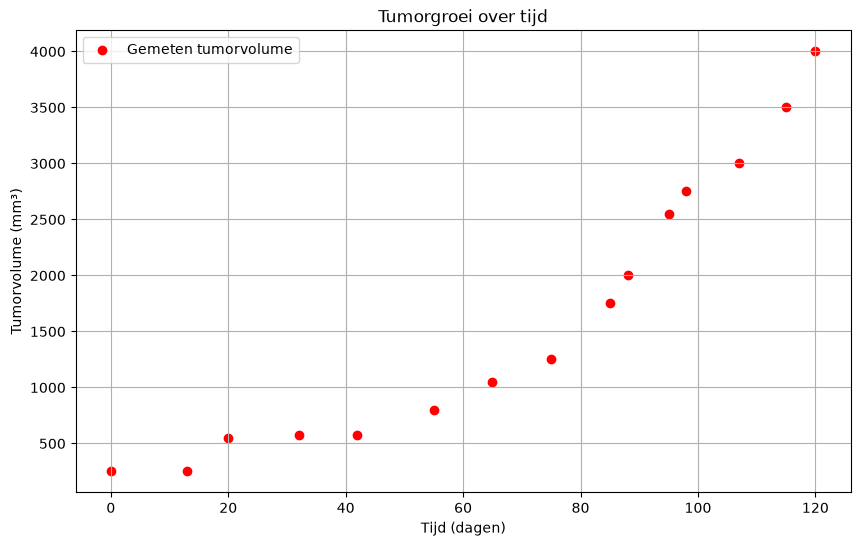

In [17]:
def plot_data(ts_input, ys_input):
    plt.figure(figsize=(10, 6))

    plt.scatter(ts_input, ys_input, color="red", label="Gemeten tumorvolume")

    plt.xlabel("Tijd (dagen)")
    plt.ylabel("Tumorvolume (mm³)")
    plt.title("Tumorgroei over tijd")

    plt.legend()
    plt.grid(True)
    plt.show()


plot_data(ts_input, ys_input)

De grafiek toont de ontwikkeling van het tumorvolume over een periode van 120 dagen. Het tumorvolume neemt toe van 250 mm^3 bij de eerste meting tot 4000 mm^3 bij de laatste meting. De groei verloopt niet volledig gelijkmatig. 

Daarnaast zijn de meetmomenten niet met vaste meetintervallen uitgevoerd: het aantal dagen tussen opeenvolgende metingen verschilt.

# Groeimodellen

Voor dit onderzoek is gekozen voor drie verschillende wiskundige groeimodellen: het exponentiële, logistische en Gompertz-model. 

Deze modellen zijn gekozen omdat ze op verschillende manieren tumorgroei beschrijven. 

Door de modellen met elkaar te vergelijken, kunnen we onderzoeken welk model het beste aansluit bij onze dataset. 

Daarnaast kunnen we bekijken of de tumorgroei beter wordt beschreven door onbeperkte groei of door groei waarbij de groeisnelheid op een gegeven moment afneemt.

**Exponentieel groeimodel**  

Het exponentiële model gaat uit van onbeperkte groei. Hierbij neemt het tumorvolume steeds sneller toe, omdat de groei afhankelijk is van het huidige tumorvolume.

Het exponentieel groeimodel heeft de volgende differentiaalvergelijking:
$$
\frac{dy}{dt} = r \cdot y
$$

Met de parameters:
$$
\begin{aligned}
y &= \text{Huidige tumorvolume} \\
t &= \text{Tijd in dagen} \\
r &= \text{Groeifactor}
\end{aligned}
$$

In [18]:
# Exponentieel groeimodel
def exponential_model(t, y, r, K=None):
    return r * y

Dit model kan gebruikt worden om tumorgroei te beschrijven wanneer tumorcellen zich blijven delen en er voldoende ruimte en voedingsstoffen beschikbaar zijn. Het model houdt geen rekening met beperkingen in de groei.

**Logistisch groeimodel**  

Het logistische model houdt wel rekening met een maximale groei. Het tumorvolume groeit in het begin relatief snel, maar de groei neemt af naarmate het volume dichter bij de maximale draagkracht komt.

Het logistisch groeimodel heeft de volgende differentiaalvergelijking:
$$
\frac{dy}{dt} = r \cdot y \left(1-\frac{y}{K}\right)
$$

Met de parameters:
$$
\begin{aligned}
y &= \text{Huidige tumorvolume} \\
t &= \text{Tijd in dagen} \\
r &= \text{Groeifactor} \\
K &= \text{Maximale draagkracht (maximaal tumorvolume)}
\end{aligned}
$$

In [19]:
# Logistisch groeimodel
def logistic_model(t, y, r, K):
    return r * y * (1 - y / K)

Bij tumorgroei kunnen beschikbare ruimte, voedingsstoffen en zuurstof de groei beperken. Het logistische model houdt rekening met deze beperkingen door een maximale draagkracht te gebruiken.

**Gompertz-model**  

Het Gompertz-model beschrijft groei waarbij de relatieve groeisnelheid afneemt naarmate het tumorvolume groter wordt. De groei neemt hierdoor geleidelijk af.

Het Gompertz-model heeft de volgende differentiaalvergelijking:
$$
\frac{dy}{dt} = r \cdot y \cdot \ln\left(\frac{K}{y}\right)
$$

Met de parameters:
$$
\begin{aligned}
y &= \text{Huidige tumorvolume} \\
t &= \text{Tijd in dagen} \\
r &= \text{Groeifactor} \\
K &= \text{Maximale draagkracht (maximaal tumorvolume)} \\
\ln &= \text{Natuurlijke logaritme}
\end{aligned}
$$

In [20]:
# Gompertz groeimodel
def gompertz_model(t, y, r, K):
    return r * y * math.log(K / y)

Bovenstaand is de differentiaalvergelijking van het Gompertz groeimodel te zien met de dezelfde parameters als het logistisch groeimodel:


Bij tumoren kan de relatieve groeisnelheid afnemen doordat grotere tumoren bijvoorbeeld minder goed voorzien worden van zuurstof en voedingsstoffen. Het Gompertz-model houdt rekening met deze afnemende groeisnelheid.

Zoals je kunt zien beschrijven de 3 modellen tumorgroei op verschillende manieren. Het exponentiële model gaat uit van onbeperkte groei, terwijl het logistische en Gompertz-model rekening houden met een afname van de groei. Door de modellen met dezelfde dataset te vergelijken, kunnen we bepalen welk model de gemeten tumorgroei het beste benadert.

# ODE-solvers
Om de differentiaalvergelijkingen numeriek op te lossen, hebben we drie verschillende ODE-solvers gebruikt: Euler, Heun en Runge-Kutta 4 (RK4). Deze solvers berekenen hoe het tumorvolume zich over de tijd ontwikkelt op basis van de gekozen groeimodellen.

De drie solvers gebruiken dezelfde differentiaalvergelijkingen, maar verschillen in de manier waarop ze de groeisnelheid berekenen. Hierdoor kunnen we onderzoeken welke solver de meest nauwkeurige benadering geeft.

**Euler-methode**  

De Euler-methode is het eenvoudigste van de drie methoden. Hierbij wordt de groeisnelheid één keer berekend aan het begin van iedere tijdstap. Op basis daarvan wordt het nieuwe tumorvolume geschat.

De Euler-methode werkt volgens de onderstaande formule:
$$
y_{n+1} = y_n + h \cdot f(t_n, y_n)
$$

Hierbij is:
$$
\begin{aligned}
y_n &= \text{Huidig tumorvolume} \\
y_{n+1} &= \text{Berekend tumorvolume na de tijdstap} \\
h &= \text{Grootte van de tijdstap} \\
f(t_n, y_n) &= \text{Groeisnelheid aan het begin van de tijdstap}
\end{aligned}
$$



In [21]:
# ODE-solver met Euler
def euler_solver(ts_input, ys_input, model, r, K):
    # Initialisatie
    t, y = ts_input[0], ys_input[0]
    ts_euler, ys_euler = [t], [y]

    # ODE-solver
    for i in range(len(ts_input) - 1):
        dt = ts_input[i + 1] - ts_input[i]

        # Pakt de afgeleide van het model
        dydt1 = model(t, y, r, K)

        # Update van Euler
        t = t + dt
        y = y + dydt1 * dt

        # Bewaar tussenresultaten
        ts_euler.append(t)
        ys_euler.append(y)

    # Return de resultaten
    return ts_euler, ys_euler

**Heun-methode**  

De Heun-methode is een verbetering van de Euler-methode. Hierbij wordt de groeisnelheid twee keer berekend: één keer aan het begin van de tijdstap en één keer bij de voorspelde eindwaarde. Vervolgens wordt het gemiddelde van deze twee groeisnelheden gebruikt.

De Heun-methode werkt volgens de onderstaande formule:
$$
k_1 = f(t_n, y_n)
$$

$$
k_2 = f(t_n+h, y_n+h\cdot k_1)
$$

$$
y_{n+1} = y_n+\frac{h}{2}(k_1+k_2)
$$

Hierbij is:
$$
\begin{aligned}
y_n &= \text{Huidig tumorvolume} \\
y_{n+1} &= \text{Berekend tumorvolume na de tijdstap} \\
t_n &= \text{Huidige tijdstip} \\
h &= \text{Grootte van de tijdstap} \\
k_1 &= \text{Groeisnelheid aan het begin van de tijdstap} \\
k_2 &= \text{Voorspelde groeisnelheid aan het einde van de tijdstap}
\end{aligned}
$$

In [22]:
# ODE-solver met Heun
def heun_solver(ts_input, ys_input, model, r, K):
    # Initialisatie
    t, y = ts_input[0], ys_input[0]
    ts_heun, ys_heun = [t], [y]

    # ODE-solver
    for i in range(len(ts_input) - 1):
        dt = ts_input[i + 1] - ts_input[i]

        # Eerste update volgens Heun
        dydt1 = model(t, y, r, K)
        t1 = t + dt
        y1 = y + dydt1 * dt

        # Tweede update volgens Heun
        dydt2 = model(t1, y1, r, K)
        t = t + dt
        y = y + (dydt1 + dydt2) / 2.0 * dt

        # Bewaar tussenresultaten
        ts_heun.append(t)
        ys_heun.append(y)

    # Return de resultaten
    return ts_heun, ys_heun

**Runge-Kutta 4-methode (RK4)**  

De Runge-Kutta 4-methode is de meest uitgebreide van de drie methoden. Hierbij wordt de groeisnelheid vier keer berekend: aan het begin, twee keer halverwege en aan het einde van de tijdstap. Deze waarden worden met verschillende gewichten gecombineerd om een nauwkeuriger resultaat te berekenen.

De Runge-Kutta 4-methode werkt volgens de onderstaande formule:
$$
k_1 = f(t_n, y_n)
$$

$$
k_2 = f\left(t_n+\frac{h}{2}, y_n+\frac{h}{2}k_1\right)
$$

$$
k_3 = f\left(t_n+\frac{h}{2}, y_n+\frac{h}{2}k_2\right)
$$

$$
k_4 = f(t_n+h, y_n+h\cdot k_3)
$$

$$
y_{n+1}=y_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4)
$$

Hierbij is:
$$
\begin{aligned}
y_n &= \text{Huidig tumorvolume} \\
y_{n+1} &= \text{Berekend tumorvolume na de tijdstap} \\
t_n &= \text{Huidige tijdstip} \\
h &= \text{Grootte van de tijdstap} \\
k_1 &= \text{Groeisnelheid aan het begin} \\
k_2 &= \text{Groeisnelheid halverwege, gebaseerd op } k_1 \\
k_3 &= \text{Groeisnelheid halverwege, gebaseerd op } k_2 \\
k_4 &= \text{Groeisnelheid aan het einde, gebaseerd op } k_3
\end{aligned}
$$

In [23]:
# ODE-solver met Runge-Kutta 4
def rk4_solver(ts_input, ys_input, model, r, K):
    # Initialisatie
    t, y = ts_input[0], ys_input[0]
    ts_rk4, ys_rk4 = [t], [y]

    # Loop door de tijdstappen en voer RK4 uit
    for i in range(len(ts_input) - 1):
        dt = ts_input[i + 1] - ts_input[i]

        # Bereken de vier k-waarden voor RK4
        k1 = model(t, y, r, K)
        k2 = model(t + dt / 2, y + k1 * dt / 2, r, K)
        k3 = model(t + dt / 2, y + k2 * dt / 2, r, K)
        k4 = model(t + dt, y + k3 * dt, r, K)

        # Update van y en t volgens RK4
        y = y + (k1 + 2 * k2 + 2 * k3 + k4) / 6 * dt
        t = t + dt

        # Bewaar de resultaten
        ts_rk4.append(t)
        ys_rk4.append(y)

    # Return de resultaten
    return ts_rk4, ys_rk4

# Monte Carlo-optimalisatie

Om de groeimodellen zo goed mogelijk aan te laten sluiten op onze dataset, hebben we gebruikgemaakt van een Monte Carlo-simulatie. Hiermee proberen we de beste waarden voor de parameters van ieder groeimodel te vinden.

De exacte waarden van de groeiparameters zijn vooraf niet bekend. Daarom laten we Python willekeurige parameterwaarden genereren en onderzoeken we welke combinatie het beste overeenkomt met de gemeten tumorvolumes.

**Werking van de Monte Carlo-simulatie**

De simulatie bestaat uit de volgende stappen:
1. Python genereert willekeurige waarden voor de parameters van het groeimodel.
2. Met deze parameters wordt het tumorvolume berekend met behulp van de verschillende solvers.
3. De berekende tumorvolumes worden vergeleken met de daadwerkelijke meetgegevens.
4. Hiervoor wordt de Mean Squared Error (MSE) berekend.
5. Dit proces wordt meerdere keren herhaald.
6. Uiteindelijk wordt de combinatie van parameters met de laagste MSE geselecteerd.

We hebben gekozen voor 5000 simulaties per groeimodel. Hierdoor worden verschillende parametercombinaties getest en kunnen we onderzoeken welke combinatie de beste aansluiting geeft op onze dataset.

**Parameters**  

Voor ieder model worden andere parameters gegenereerd:
- Exponentieel model: alleen de groeifactor (r).
- Logistisch model: de groeifactor (r) en maximale draagkracht (K).
- Gompertz-model: de groeifactor (r) en maximale draagkracht (K).

De willekeurige waarden worden binnen vooraf (door ons) ingestelde grenzen gegenereerd:
De groeifactor (r) heeft een ondergrens van 0.001 en een bovengrens van 0.1.
De maximale draagkracht (K) heeft een ondergrens van 4000 en een bovengrens van 10000.

De grenzen bepalen binnen welk bereik Python naar geschikte parameterwaarden zoekt.

In [24]:
def monte_carlo_simulation(ts_input, ys_input, model, solver, model_name, num_simulations):
    results = []

    for i in range(num_simulations):

        # Kies willekeurige waarden voor de parameters
        r = random.uniform(0.001, 0.1)

        if model_name == "Exponentieel":
            K = None
        else:
            K = random.uniform(4000, 10000)

        # Bereken de MSE
        mse = calculate_model_error(
            ts_input, ys_input, model, solver, r, K
        )

        results.append((r, K, mse))

    return results

**Berekenen van de fout (MSE)**  

Om te bepalen hoe goed een parametercombinatie werkt, gebruiken we de Mean Squared Error (MSE). Hierbij worden de voorspelde tumorvolumes vergeleken met de gemeten tumorvolumes.

De formule voor het berekenen van de Mean Squared Error is:
$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

Met de volgende parameters:
$$
\begin{aligned}
n &= \text{Aantal meetpunten} \\
y_i &= \text{Gemeten tumorvolume} \\
\hat{y}_i &= \text{Voorspeld tumorvolume} \\
MSE &= \text{Gemiddelde gekwadrateerde fout}
\end{aligned}
$$

Een lage MSE houdt in dat de voorspelde tumorvolumes relatief dicht bij de daadwerkelijke meetgegevens liggen. Daarom selecteren we uiteindelijk de parametercombinatie met de laagste MSE.

In [25]:
# Bereken de Mean Squared Error
def calculate_mse(ys_input, ys_model):
    total = 0

    for i in range(len(ys_input)):
        difference = ys_input[i] - ys_model[i]
        total = total + difference ** 2

    mse = total / len(ys_input)

    return mse

def calculate_model_error(ts_input, ys_input, model, solver, r, K):
    ts_model, ys_model = solver(
        ts_input, ys_input, model, r, K
    )

    mse = calculate_mse(ys_input, ys_model)

    return mse

**Toepassing op onze dataset**  

Voor onze dataset hebben we de Monte Carlo-simulatie toegepast op drie groeimodellen, gecombineerd met drie ODE-solvers (Euler, Heun en RK4). Dit geeft in totaal negen combinaties, waarbij we per combinatie 5000 simulaties uitvoeren.

Per simulatie worden willekeurige parameterwaarden gekozen en wordt de voorspelde tumorgroei vergeleken met de meetgegevens uit onze dataset. Op basis van de MSE selecteren we per combinatie de parameterwaarden die het beste aansluiten op de gemeten tumorvolumes.

De laagste MSE gebruiken we vervolgens ook bij het berekenen van de AIC, BIC en AICc. Hiermee kunnen we de modellen verder met elkaar vergelijken.

In [26]:
models = {
    "Exponentieel": exponential_model,
    "Logistisch": logistic_model,
    "Gompertz": gompertz_model
}

solvers = {
    "Euler": euler_solver,
    "Heun": heun_solver,
    "RK4": rk4_solver
}

Hier worden de drie groeimodellen en de drie ODE-solvers vastgelegd in dictionaries, zodat ze later gecombineerd kunnen worden.

In [27]:
def run_optimization(ts_input, ys_input, models, solvers):
    all_results = {}

    for model_name, model in models.items():
        for solver_name, solver in solvers.items():

            name = model_name + " + " + solver_name

            all_results[name] = monte_carlo_simulation(
                ts_input, ys_input, model, solver,
                model_name, 5000
            )

    return all_results

De bovenstaande functie voert voor elke combinatie van groeimodel en ODE-solver 5000 Monte Carlo-simulaties uit en slaat de resultaten op in een dictionary.

In [28]:
def print_best_results(results):

    for name, simulations in results.items():

        # Zoek het resultaat met de laagste MSE
        best_result = simulations[0]

        for result in simulations:
            if result[2] < best_result[2]:
                best_result = result

        # Print de beste parameters en MSE
        print(name)
        print("Beste r:", best_result[0])

        if "Exponentieel" not in name:
            print("Beste K:", best_result[1])

        print("Laagste MSE:", best_result[2])
        print()


results = run_optimization(ts_input, ys_input, models, solvers)

print_best_results(results)

Exponentieel + Euler
Beste r: 0.02618330775112834
Laagste MSE: 19915.08534926099

Exponentieel + Heun
Beste r: 0.023463751766534133
Laagste MSE: 19191.57015594636

Exponentieel + RK4
Beste r: 0.023267282861198318
Laagste MSE: 19126.770035108064

Logistisch + Euler
Beste r: 0.029671946769228776
Beste K: 9441.682134105522
Laagste MSE: 20179.884620156805

Logistisch + Heun
Beste r: 0.026920496149351842
Beste K: 9717.100343379952
Laagste MSE: 25342.06644252148

Logistisch + RK4
Beste r: 0.026573177319699288
Beste K: 9791.963799221212
Laagste MSE: 25677.243696808615

Gompertz + Euler
Beste r: 0.011197092776484147
Beste K: 9919.685116409491
Laagste MSE: 84834.05120168827

Gompertz + Heun
Beste r: 0.010371812466431662
Beste K: 9866.853168333484
Laagste MSE: 101293.61110884581

Gompertz + RK4
Beste r: 0.010155125413841164
Beste K: 9984.704244480694
Laagste MSE: 102868.03470052374



Deze functie selecteert per combinatie van groeimodel en ODE-solver de simulatie met de laagste MSE en print de bijbehorende beste waarden voor r en K. De resultaten worden vervolgens als output weergegeven.

# Resultaten

In [29]:
# Visualiseer na optimalisatie van de parameters
def plot_optimized_results(ts_input, ys_input, results, models, solvers):
    plt.figure(figsize=(12, 7))

    plt.plot(ts_input, ys_input, 'ok', label='Meetgegevens')

    for model_name, model in models.items():

        for solver_name, solver in solvers.items():

            name = model_name + " + " + solver_name

            # Zoek de beste parameters
            simulations = results[name]
            best_result = simulations[0]

            for result in simulations:
                if result[2] < best_result[2]:
                    best_result = result

            # Bereken de tumorgroei met de beste parameters
            ts_model, ys_model = solver(
                ts_input, ys_input, model,
                best_result[0], best_result[1]
            )

            plt.plot(ts_model, ys_model, label=name)

    plt.grid(True)
    plt.legend()
    plt.xlabel('Tijd (dagen)')
    plt.ylabel('Tumorvolume (mm³)')
    plt.title('Tumorgroei met geoptimaliseerde parameters')
    plt.show()

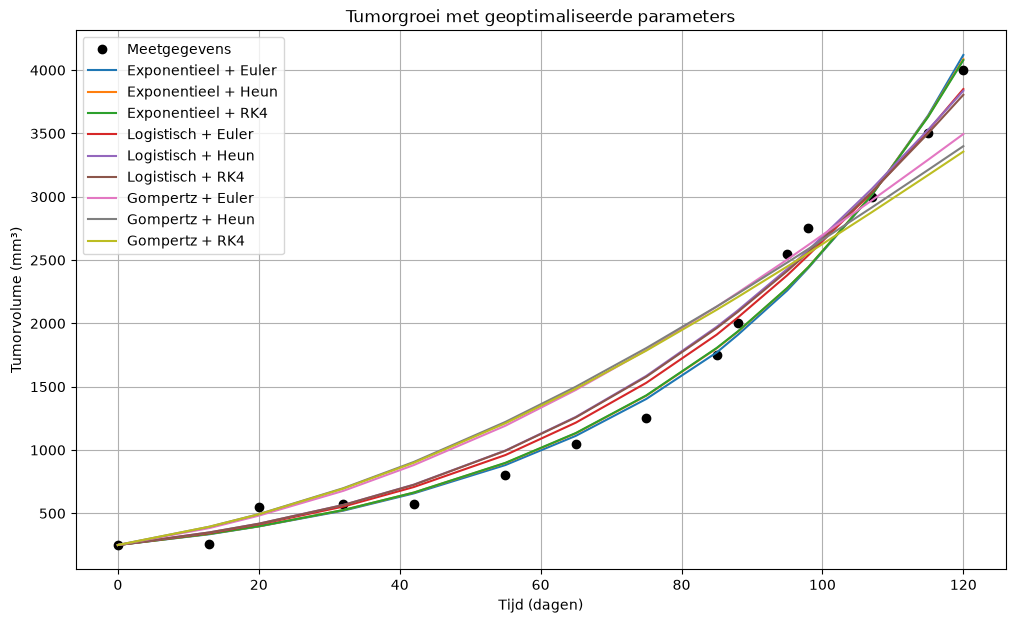

In [30]:
plot_optimized_results(
    ts_input,
    ys_input,
    results,
    models,
    solvers
)

# Modelvergelijking

Als laatste willen we de verschillende modellen met elkaar vergelijken. Een van de waardes waarmee dat kan is de hiervoor berekende MSE, die zo laag mogelijk is, is het best. Verder zijn er nog 3 andere waardes waar we naar zullen kijken, namelijk Bayes Information Criterion (BIC), Akaike Information Criteerion (AIC) en de corrigeerde maat daarvan (AICc). De volgende formules beschrijven deze waarbij *n* het aantal datapunten en *k* het aantal parameters beschrijft.

\begin{align} \text{BIC} &= n \cdot \ln \left( \text{MSE} \right) + \ln(n) \cdot k \\ \text{AIC} &= n \cdot \ln \left( \text{MSE} \right) + 2 k \\ \text{AIC}_c &= n \cdot \ln \left( \text{MSE} \right) + \frac{2 k \cdot n}{n-k-1} \end{align}

Het grootste verschil tussen deze drie en de MSE is dat deze rekening houden met de hoeveelheid parameters van het model. Meer parameters leidt tot een beter passend model, maar teveel parameters leidt tot overfitting van het model op de data, het model is zo erg toegespitst op de data dat de trend van de data buiten beeld raakt en het model kan niet meer nuttige voorspellingen buiten de aanwezige data maken. Hier wordt dus afgestraft wanneer de modellen slecht overeenkomen met de data, maar ook wanneer modellen onnodig veel parameters hiervoor gebruiken. BIC neigt naar simpele modellen met weinig parameters, vooral bij grote datasets. AIC telt minder zwaar aan veel parameters, AICc is gecorrigeerd ten opzichte van AIC voor het omgaan met kleine datasets.

In [44]:
# berekenen BIC, AIC & AICc
def calculate_BIC_AIC_AICc(ys_input, results):
    
    best_result = results[0]
    
    for result in results:
        if result[2] < best_result[2]:
            best_result = result


    r, K, mse = best_result
    n, k = len(ys_input), len(best_result)-1 #mse erafhalen om aantal parameters te krijgen
    
    BIC  = n * math.log(mse) + k * math.log(n)
    AIC  = n * math.log(mse) + k * 2.0
    AICc = n * math.log(mse) + k * 2.0 * n/(n-k-1) 
   
   
    return f"{mse = :.1f},\n {BIC  = :.1f},\n {AIC  = :.1f},\n {AICc = :.1f}"

Zoals hierboven benoemd zullen we per model de solver met het laagste MSE na de monte carlo optimalisatie gebruiken. Aan de hand van de resultaten hierboven zijn dat voor het exponentiele model + RK4; voor het logistische model + euler & voor het Grompertz model + euler. Met deze gaan we dus verder.

In [45]:
best_exponentieel_model = results["Exponentieel + RK4"]
best_logistisch_model = results["Logistisch + Euler"]
best_grompertz_model = results["Gompertz + Euler"]

print("Exponentieel + RK4\n", calculate_BIC_AIC_AICc(ys_input, best_exponentieel_model))
print("Logistisch + Euler\n", calculate_BIC_AIC_AICc(ys_input, best_logistisch_model))
print("Gompertz + Euler\n",calculate_BIC_AIC_AICc(ys_input, best_grompertz_model))



Exponentieel + RK4
 mse = 19126.8,
 BIC  = 153.3,
 AIC  = 151.9,
 AICc = 152.9
Logistisch + Euler
 mse = 20179.9,
 BIC  = 154.1,
 AIC  = 152.7,
 AICc = 153.7
Gompertz + Euler
 mse = 84834.1,
 BIC  = 175.6,
 AIC  = 174.2,
 AICc = 175.2


Voor alle drie deze waarden geldt hetzelfde als voor de MSE; hoe lager hoe beter het model. Verder is een verschil van minder dan 2 tussen twee verschillende modellen een signaal dat de verschillen verwaarloosbaar zijn en aan de hand hiervan niet bepaald kan worden welke beter is. Dan zullen andere factoren de doorslag moeten geven.

# Conclusie

De combinatie van MSE, BIC, AIC & AICc voor de 3 modellen met hun beste solver zoals hierboven te zien zijn, resulteert in 2 opties. De kleinste MSE geldt voor het exponentieële model in combinatie met de RK4 solver. Maar de MSE van het logistische model met de Euler solver ligt daar niet ver boven. Als we voor beide naar kijken, die verbeterd is voor kleine datasets, wat dit is, dan schelen die 0.8. Dit is minder dan 2 en de modellen zijn dus beide acceptabel volgens deze maatstaven. Het Gompertz model valt in beide gevallen dus duidelijk af. 

Omdat voor alle 4 de getallen het exponentieële model licht kleiner waarden heeft, denken wij dat dat de beste optie is.